<a href="https://colab.research.google.com/github/ollihansen90/Mathe-SH/blob/main/Pixelwelten_Wasser.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget https://github.com/ollihansen90/Mathe-SH/raw/refs/heads/main/data/tiles.npy

--2026-11-25 13:46:43--  https://github.com/ollihansen90/Mathe-SH/raw/refs/heads/main/data/tiles.npy
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/ollihansen90/Mathe-SH/refs/heads/main/data/tiles.npy [following]
--2026-11-25 13:46:43--  https://raw.githubusercontent.com/ollihansen90/Mathe-SH/refs/heads/main/data/tiles.npy
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 202880 (198K) [application/octet-stream]
Saving to: ‘tiles.npy’

tiles.npy           100%[===================>] 198.12K  --.-KB/s    in 0.02s   

2026-11-25 13:46:43 (9.07 MB/s) - ‘tiles.npy’ saved [202880/202880]



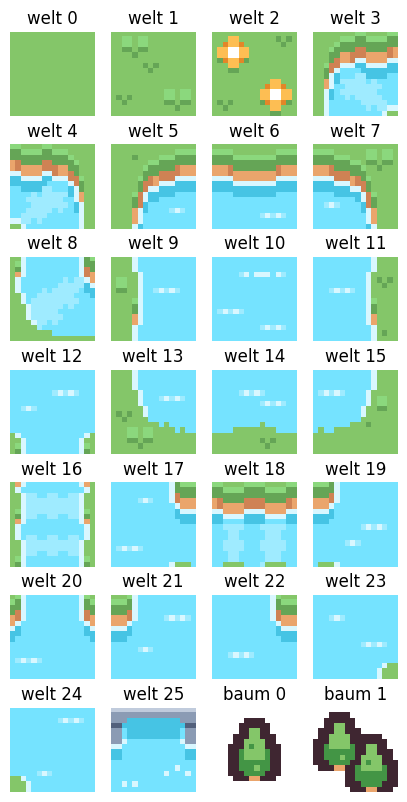

In [2]:
import numpy as np
import matplotlib.pyplot as plt

tiles = np.load("tiles.npy")
t_welt = [0,1,2,3,4,18,19,20,21,36,37,38,39,54,55,56,57,72,73,74,75,90,91,92,93,148]
t_baeume = [94, 112]

welt_tiles = tiles[t_welt]
baum_tiles = tiles[t_baeume]

plt.figure(figsize=[5,10])
start = 0
for i in range(0,len(welt_tiles)):
    plt.subplot(7,4,i+1)
    plt.imshow(welt_tiles[i])
    plt.title(f"welt {i}")
    plt.axis("off")
plt.subplot(7,4,27)
plt.imshow(baum_tiles[0])
plt.title("baum 0")
plt.axis("off")
plt.subplot(7,4,28)
plt.imshow(baum_tiles[1])
plt.title("baum 1")
plt.axis("off")
plt.show()

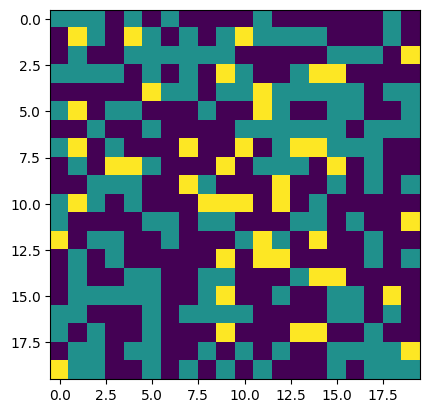

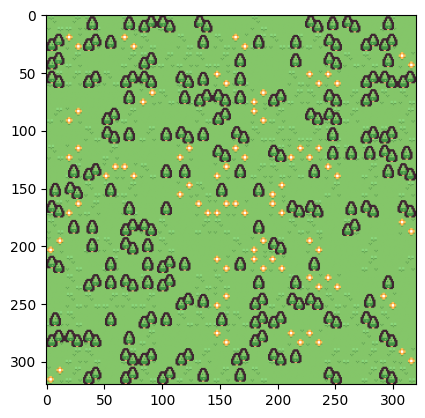

In [40]:
welt_h = 20
welt_b = 20

welt_idc = np.zeros([welt_h, welt_b])

for i in range(welt_h):
    for j in range(welt_b):
        z =np.random.random()
        if z<0.5:
            welt_idc[i,j] = 0
        elif z<0.9:
            welt_idc[i,j] = 1
        else:
            welt_idc[i,j] = 2

plt.figure()
plt.imshow(welt_idc)
plt.show()

welt_h = 20
welt_b = 20
baum_idc = np.clip(np.random.randint(-2,3, (welt_h, welt_b)), a_min=0, a_max=2)

welt = np.zeros([16*welt_h, 16*welt_b,4])
h, b = welt_idc.shape
wasser = np.zeros_like(welt_idc)
welt_idc[wasser>0] = wasser[wasser>0]

def weltify(welt_idc, baum_idc, tilelist, baeume):
    for i in range(h):
        for j in range(b):
            w_idx = int(welt_idc[i,j])
            tile = tilelist[w_idx]/255
            if w_idx in [1,2] and np.random.rand()<0.5:
                tile = tile[:,::-1]

            b_idx = int(baum_idc[i,j])
            if b_idx>0 and w_idx in [0,1]:
                baum = baeume[b_idx-1]/255
                if np.random.rand()<0.5:
                    baum = baum[:,::-1]

                alpha = baum[:,:,[3]]
                tile = tile*(1-alpha) + baum*alpha


            welt[16*i:16*i+16, 16*j:16*j+16,:] = tile
    return welt

plt.figure()
plt.imshow(weltify(welt_idc, baum_idc, welt_tiles,baum_tiles))
plt.show()

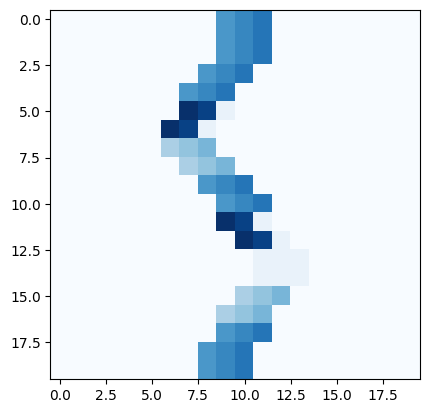

In [34]:
h, b = 20, 20
wasser = np.zeros((h, b))

# Vorgegebener Flussverlauf
fluss_x = [10,10,10,9,8,8,7,7,8,9,
           10,10,11,12,12,11,10,10,9,9]

plt.figure()
plt.imshow(wasser, cmap="Blues")
plt.show()